# Poisson方程式から有限要素法の弱形式を導出する

## 概要

Poisson方程式に試験関数を掛け、部分積分によって弱形式を導く。境界条件の扱いを整理し、一次元の線形要素で行列を組み立てる。Pythonで近似解と厳密解を比較し、誤差の減り方まで確認する。

## 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SciPy、SymPy、Matplotlibを使用する。以下のセルで実際のバージョンを表示する。上から順に実行する。図は `101_nb_files` にSVG形式で保存する。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from IPython.display import Math, SVG, display
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix  # 仮想環境内での実行を確認する。
print("実行環境: wa-src(3.14.6)")
print(f"OS: {platform.system()}, Python: {platform.python_version()}")
for module in (np, scipy, sp, matplotlib):
    print(f"{module.__name__}: {module.__version__}")

# Notebookのディレクトリ、またはリポジトリ直下から実行できる。
base = Path.cwd()
if (base / "rec/cae/101/101_nb.ipynb").is_file():
    base = base / "rec/cae/101"
image_dir = base / "101_nb_files"
image_dir.mkdir(exist_ok=True)
np.set_printoptions(formatter={"float_kind": lambda x: f"{x:.2e}"})
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})


def save_figure(fig, filename):
    """小数を有効数字3桁に統一し、保存したSVGをそのまま表示する。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.2e}"))
            axis.set_minor_formatter(NullFormatter())
    fig.tight_layout()
    path = image_dir / filename
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))

実行環境: wa-src(3.14.6)
OS: Darwin, Python: 3.14.6
numpy: 2.5.4
scipy: 1.18.1
sympy: 1.14.0
matplotlib: 3.11.2


## 1. 強形式と境界条件

有界で連結な領域$\Omega$を考え、境界はLipschitz連続とする。境界をDirichlet部分$\Gamma_D$とNeumann部分$\Gamma_N$に分け、$\Gamma_D$は正の境界測度を持つとする。未知関数を$u$、外向き単位法線を$\mathbf{n}$とすると、強形式は次である。

$$
\displaystyle
-\Delta u=f\ \text{in }\Omega,\qquad
u=u_D\ \text{on }\Gamma_D,\qquad
\nabla u\cdot\mathbf{n}=g\ \text{on }\Gamma_N.
$$

$f$は領域内の生成項、$g$は法線方向の微分値である。ここでは流束$-\nabla u$の法線成分とは符号が逆である。強形式では、方程式を点ごとに満たすための二階微分が必要になる。

## 2. 部分積分で弱形式を作る

まず$u,v$が十分滑らかな場合に計算する。$\Gamma_D$上で0となる任意の試験関数$v$を掛け、領域全体で積分する。

$$
\displaystyle
-\int_\Omega v\Delta u\,d\mathbf{x}=\int_\Omega fv\,d\mathbf{x}.
$$

積の微分と発散定理を順に使う。

$$
\displaystyle
\begin{aligned}
\nabla\cdot(v\nabla u)&=\nabla v\cdot\nabla u+v\Delta u,\\
v\Delta u&=\nabla\cdot(v\nabla u)-\nabla v\cdot\nabla u,\\
-\int_\Omega v\Delta u\,d\mathbf{x}
&=-\int_\Omega\nabla\cdot(v\nabla u)\,d\mathbf{x}
+\int_\Omega\nabla v\cdot\nabla u\,d\mathbf{x}\\
&=-\int_{\partial\Omega}v\nabla u\cdot\mathbf{n}\,ds
+\int_\Omega\nabla v\cdot\nabla u\,d\mathbf{x}.
\end{aligned}
$$

境界積分を分けると、$\Gamma_D$上では$v=0$、$\Gamma_N$上では$\nabla u\cdot\mathbf{n}=g$である。

$$
\displaystyle
\int_{\partial\Omega}v\nabla u\cdot\mathbf{n}\,ds
=\underbrace{\int_{\Gamma_D}v\nabla u\cdot\mathbf{n}\,ds}_{0}
+\int_{\Gamma_N}vg\,ds.
$$

これを代入して境界項を右辺へ移すと、弱形式を得る。

$$
\displaystyle
\boxed{\int_\Omega\nabla u\cdot\nabla v\,d\mathbf{x}
=\int_\Omega fv\,d\mathbf{x}+\int_{\Gamma_N}gv\,ds}
$$

Dirichlet条件は関数の制約、Neumann条件は右辺の境界積分として入る。私は境界項を残す方が、符号を確認しやすいと感じる。

### なぜ「弱い」のか

$H^1(\Omega)$は関数自身と一階の弱微分が二乗可積分な関数の空間である。$f\in L^2(\Omega)$、$g\in L^2(\Gamma_N)$とし、$u_D$は$H^1$関数の境界値として実現できるとする。

$$
\displaystyle
U=\{w\in H^1(\Omega):w|_{\Gamma_D}=u_D\},\qquad
V=\{v\in H^1(\Omega):v|_{\Gamma_D}=0\}.
$$

境界値はトレースの意味で指定する。弱問題は「すべての$v\in V$に対して上式を満たす$u\in U$を求める」問題である。一階微分だけを要求するので、折れ線状の連続関数も使える。十分滑らかな解では強形式と対応するが、弱形式にしただけでは近似は入らない。

## 3. 有限個の未知数へ置き換える

$u_D=0$とする。$V$の有限次元部分空間$V_h$の基底を$\phi_1,\ldots,\phi_m$とする。近似はここで導入する。

$$
\displaystyle
\begin{aligned}
u_h&=\sum_{j=1}^m U_j\phi_j,\qquad v_h=\phi_i,\\
\int_\Omega\nabla\left(\sum_jU_j\phi_j\right)\cdot\nabla\phi_i\,d\mathbf{x}
&=\int_\Omega f\phi_i\,d\mathbf{x}+\int_{\Gamma_N}g\phi_i\,ds,\\
\sum_j\underbrace{\left(\int_\Omega\nabla\phi_j\cdot\nabla\phi_i\,d\mathbf{x}\right)}_{K_{ij}}U_j
&=\underbrace{\int_\Omega f\phi_i\,d\mathbf{x}+\int_{\Gamma_N}g\phi_i\,ds}_{F_i}.
\end{aligned}
$$

各$i=1,\ldots,m$の式をまとめると、剛性行列$\mathbf{K}$、未知ベクトル$\mathbf{U}$、荷重ベクトル$\mathbf{F}$の連立方程式になる。

$$
\displaystyle
\boxed{\mathbf{K}\mathbf{U}=\mathbf{F}}
$$

$u_D\ne0$なら境界値を満たす関数を先に取り、その関数と境界で0の未知関数の和で表す。

## 4. 一次元の線形要素

$-u''=2$、$0\lt x\lt1$、$u(0)=u(1)=0$を解く。二回積分して境界条件を代入する。

$$
\displaystyle
u''=-2,\quad u'=-2x+C_1,\quad u=-x^2+C_1x+C_2,\quad
C_2=0,\ C_1=1,\quad u=x(1-x).
$$

$N$等分し、$x_i=i/N$、$h=1/N$とする。要素$[x_e,x_{e+1}]$内で$t=x-x_e$と置けば、局所基底は$N_1=1-t/h$、$N_2=t/h$である。

$$
\displaystyle
\begin{aligned}
N_1'&=-1/h,\quad N_2'=1/h,\\
K^e_{11}=K^e_{22}&=\int_0^h\frac{1}{h^2}\,dt=\frac1h,\\
K^e_{12}=K^e_{21}&=\int_0^h\frac{-1}{h^2}\,dt=-\frac1h,\\
F^e_1&=\int_0^h2(1-t/h)\,dt=[2t-t^2/h]_0^h=h,\\
F^e_2&=\int_0^h2t/h\,dt=[t^2/h]_0^h=h.
\end{aligned}
$$

したがって各要素の行列とベクトルは次になる。SymPyでも積分して確認する。

$$
\displaystyle
\mathbf{K}^e=\frac1h\begin{bmatrix}1&-1\\-1&1\end{bmatrix},\qquad
\mathbf{F}^e=h\begin{bmatrix}1\\1\end{bmatrix}.
$$

<IPython.core.display.Math object>

<IPython.core.display.Math object>

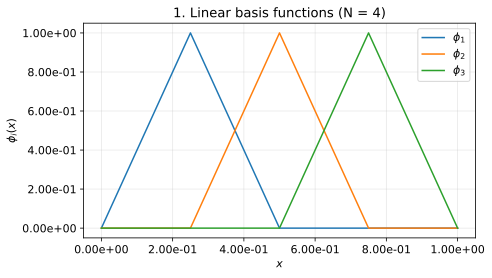

In [2]:
t, h_symbol = sp.symbols("t h", positive=True)
shape = [1 - t / h_symbol, t / h_symbol]
ke = sp.Matrix(2, 2, lambda i, j: sp.integrate(
    sp.diff(shape[i], t) * sp.diff(shape[j], t), (t, 0, h_symbol)
))
fe = sp.Matrix([sp.integrate(2 * n, (t, 0, h_symbol)) for n in shape])
assert ke == sp.Matrix([[1, -1], [-1, 1]]) / h_symbol
assert fe == sp.Matrix([h_symbol, h_symbol])
display(Math(r"\mathbf{K}^e=" + sp.latex(ke)))
display(Math(r"\mathbf{F}^e=" + sp.latex(fe)))

# 大域基底は隣接する二要素にまたがる帽子型の関数になる。
grid = np.linspace(0, 1, 401)
fig, ax = plt.subplots(figsize=(7, 4))
for i in range(1, 4):
    phi = np.maximum(1 - np.abs(grid - i / 4) / (1 / 4), 0)
    ax.plot(grid, phi, label=rf"$\phi_{i}$")
ax.set(xlabel="$x$", ylabel=r"$\phi_i(x)$", title="1. Linear basis functions (N = 4)")
ax.legend()
ax.grid(alpha=0.300)
save_figure(fig, "01_basis.svg")

### 組み立てと境界値の除去

共有節点の成分を加算する。内部節点では対角成分が$2/h$、隣接成分が$-1/h$、荷重が$2h$になる。端点の既知値0を除くと、未知数は$N-1$個である。以下はこの問題専用の実装である。右辺を変える場合は要素荷重の積分も変える。

{'K': array([[8.00e+00, -4.00e+00, 0.00e+00],
       [-4.00e+00, 8.00e+00, -4.00e+00],
       [0.00e+00, -4.00e+00, 8.00e+00]]),
 'F': array([5.00e-01, 5.00e-01, 5.00e-01]),
 'U': array([1.88e-01, 2.50e-01, 1.87e-01])}
{'residual_norm': '1.92e-16'}


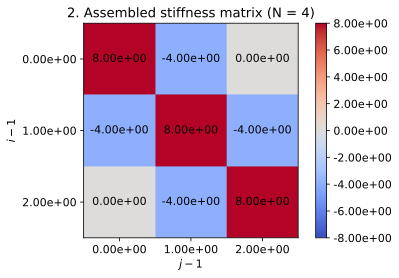

In [3]:
def solve_poisson(n):
    """-u'' = 2、両端0を一様メッシュの一次要素で解く。"""
    nodes = np.linspace(0, 1, n + 1)
    h = 1 / n
    local_k = np.array([[1, -1], [-1, 1]]) / h
    rows, cols, values = [], [], []
    load = np.zeros(n + 1)
    for e in range(n):
        ids = [e, e + 1]
        load[ids] += h  # 各局所節点の荷重はhである。
        for a in range(2):
            for b in range(2):
                rows.append(ids[a])
                cols.append(ids[b])
                values.append(local_k[a, b])
    # CSRへの変換時に、同じ節点対の寄与が加算される。
    stiffness = coo_matrix((values, (rows, cols)), shape=(n + 1, n + 1)).tocsr()
    interior_k = stiffness[1:-1, 1:-1]
    interior_f = load[1:-1]
    solution = np.zeros(n + 1)
    solution[1:-1] = spsolve(interior_k, interior_f)
    return nodes, solution, interior_k, interior_f


nodes, solution, stiffness, load = solve_poisson(4)
pprint({"K": stiffness.toarray(), "F": load, "U": solution[1:-1]}, sort_dicts=False)
residual = np.linalg.norm(stiffness @ solution[1:-1] - load)
pprint({"residual_norm": f"{residual:.2e}"})

fig, ax = plt.subplots(figsize=(6, 4))
mesh = ax.imshow(stiffness.toarray(), cmap="coolwarm", vmin=-8, vmax=8)
ax.set(xticks=range(3), yticks=range(3), xlabel="$j-1$", ylabel="$i-1$",
       title="2. Assembled stiffness matrix (N = 4)")
for (i, j), value in np.ndenumerate(stiffness.toarray()):
    ax.text(j, i, f"{value:.2e}", ha="center", va="center")
fig.colorbar(mesh, ax=ax)
save_figure(fig, "02_stiffness.svg")

## 5. 解と誤差を確認する

この例では節点の値が厳密解と一致するが、要素内は直線なので誤差が残る。導関数も要素ごとに一定である。節点だけの比較では精度を判断できない点は注意したい。

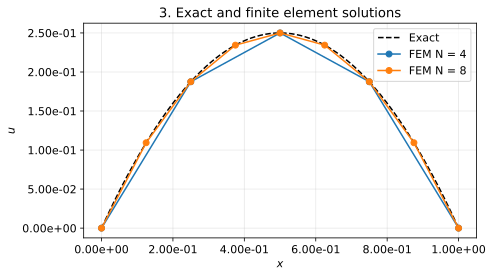

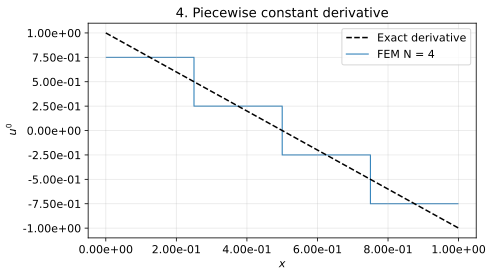

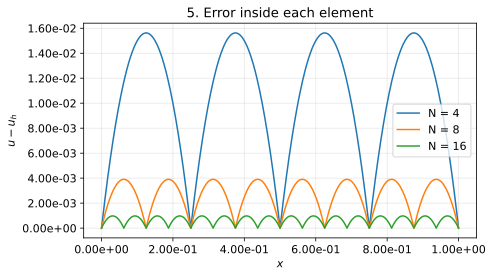

In [4]:
exact = grid * (1 - grid)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, exact, "k--", label="Exact")
for n in (4, 8):
    x, u, _, _ = solve_poisson(n)
    ax.plot(x, u, "o-", label=f"FEM N = {n}")
ax.set(xlabel="$x$", ylabel="$u$", title="3. Exact and finite element solutions")
ax.legend()
ax.grid(alpha=0.300)
save_figure(fig, "03_solution.svg")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, 1 - 2 * grid, "k--", label="Exact derivative")
ax.stairs(np.diff(solution) / np.diff(nodes), nodes, baseline=None, label="FEM N = 4")
ax.set(xlabel="$x$", ylabel="$u'$", title="4. Piecewise constant derivative")
ax.legend()
ax.grid(alpha=0.300)
save_figure(fig, "04_derivative.svg")

fig, ax = plt.subplots(figsize=(7, 4))
for n in (4, 8, 16):
    x, u, _, _ = solve_poisson(n)
    ax.plot(grid, exact - np.interp(grid, x, u), label=f"N = {n}")
ax.set(xlabel="$x$", ylabel="$u-u_h$", title="5. Error inside each element")
ax.legend()
ax.grid(alpha=0.300)
save_figure(fig, "05_error.svg")

### 誤差の大きさと収束次数

節点で一致することは、内部の式$(-U_{i-1}+2U_i-U_{i+1})/h=2h$へ$U_i=x_i(1-x_i)$を代入して確認できる。要素内の誤差$e=u-u_h$は両端で0、$e''=-2$なので$e=t(h-t)$となる。

$$
\displaystyle
\begin{aligned}
\|e\|_{L^2}^2
&=N\int_0^h t^2(h-t)^2dt
=N[h^2t^3/3-ht^4/2+t^5/5]_0^h\\
&=Nh^5(1/3-1/2+1/5)=h^4/30,\\
|e|_{H^1}^2
&=N\int_0^h(h-2t)^2dt
=N[h^2t-2ht^2+4t^3/3]_0^h=h^2/3.
\end{aligned}
$$

$Nh=1$を使った。従って$\|e\|_{L^2}=h^2/\sqrt{30}$、$|e|_{H^1}=h/\sqrt3$である。後者は導関数の誤差であり、$H^1$半ノルムと呼ぶ。数値積分には3点Gauss則を使う。この例の誤差二乗は四次多項式なので、丸め誤差を除いて正確に積分できる。

[{'N': 4, 'L2': '1.14e-02', 'H1_semi': '1.44e-01', 'p_L2': '-', 'p_H1': '-'},
 {'N': 8,
  'L2': '2.85e-03',
  'H1_semi': '7.22e-02',
  'p_L2': '2.00e+00',
  'p_H1': '1.00e+00'},
 {'N': 16,
  'L2': '7.13e-04',
  'H1_semi': '3.61e-02',
  'p_L2': '2.00e+00',
  'p_H1': '1.00e+00'},
 {'N': 32,
  'L2': '1.78e-04',
  'H1_semi': '1.80e-02',
  'p_L2': '2.00e+00',
  'p_H1': '1.00e+00'},
 {'N': 64,
  'L2': '4.46e-05',
  'H1_semi': '9.02e-03',
  'p_L2': '2.00e+00',
  'p_H1': '1.00e+00'}]
解析式と数値積分の一致を確認した。


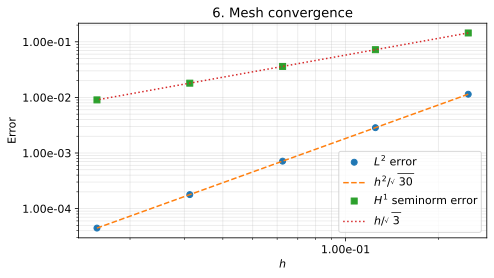

In [5]:
def error_norms(nodes, solution):
    """要素ごとに関数値と導関数の誤差を積分する。"""
    q, weights = np.polynomial.legendre.leggauss(3)
    l2_sq, h1_sq = 0, 0
    for e, h in enumerate(np.diff(nodes)):
        fraction = (q + 1) / 2
        xq = nodes[e] + h * fraction
        uh = (1 - fraction) * solution[e] + fraction * solution[e + 1]
        duh = (solution[e + 1] - solution[e]) / h
        l2_sq += h / 2 * np.dot(weights, (xq * (1 - xq) - uh) ** 2)
        h1_sq += h / 2 * np.dot(weights, (1 - 2 * xq - duh) ** 2)
    return np.sqrt(l2_sq), np.sqrt(h1_sq)


counts = np.array([4, 8, 16, 32, 64])
hs = 1 / counts
errors = np.array([error_norms(*solve_poisson(int(n))[:2]) for n in counts])
orders = np.log(errors[:-1] / errors[1:]) / np.log(2)
table = []
for i, n in enumerate(counts):
    table.append({"N": int(n), "L2": f"{errors[i, 0]:.2e}",
                  "H1_semi": f"{errors[i, 1]:.2e}",
                  "p_L2": "-" if i == 0 else f"{orders[i-1, 0]:.2e}",
                  "p_H1": "-" if i == 0 else f"{orders[i-1, 1]:.2e}"})
pprint(table, sort_dicts=False)

# 解析式との一致を調べ、誤った組み立てや積分を検出する。
np.testing.assert_allclose(errors[:, 0], hs**2 / np.sqrt(30), rtol=1.00e-8)
np.testing.assert_allclose(errors[:, 1], hs / np.sqrt(3), rtol=1.00e-8)
print("解析式と数値積分の一致を確認した。")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(hs, errors[:, 0], "o", label=r"$L^2$ error")
ax.loglog(hs, hs**2 / np.sqrt(30), "--", label=r"$h^2/\sqrt{30}$")
ax.loglog(hs, errors[:, 1], "s", label=r"$H^1$ seminorm error")
ax.loglog(hs, hs / np.sqrt(3), ":", label=r"$h/\sqrt{3}$")
ax.set(xlabel="$h$", ylabel="Error", title="6. Mesh convergence")
ax.legend()
ax.grid(which="both", alpha=0.300)
save_figure(fig, "06_convergence.svg")

## 結論

この記事では、Poisson方程式を部分積分して弱形式を導き、一次要素による離散化と誤差を確認した。

弱形式では二階微分を一階微分へ移し、境界条件を関数空間と境界積分に分けて扱う。有限次元の基底を選ぶと連立一次方程式になる。今回の例では、メッシュ幅を半分にすると$L^2$誤差は$1/4$、導関数の誤差は$1/2$になった。

参考文献：[FEniCS Project, Poisson equation](https://docs.fenicsproject.org/dolfinx/main/python/demos/demo_poisson.html)、[Langtangen・Logg・Dokken, Solving the Poisson equation](https://jsdokken.com/dolfinx-tutorial/stable/chapter1/fundamentals.html)を参照した。